# 问题描述

Using Python/C/C++/Fortran, write a finite element code to evaluate the response of plane system.

1. Your program should read a file named input that contains any useful information.

2. Your program should produce a file named output that contains the following results:

Using your completed code, solve the plane stress problem shown in Figure 1. A uniform thin plate with a central hole of radius a is subjected to uniaxial stress  . Use the finite element method to determine the stress concentration factor given the physical data $\sigma_0=1300psi, a = 0.5 in., h = 3 in, w = 6 in, E = 2.5\times10^6 psi$, and Poisson’s ratio = 0.3. In addition, compare the approximate solution of finite element method with the exact solution based on the elasticity theory, and discuss the difference between them.
 
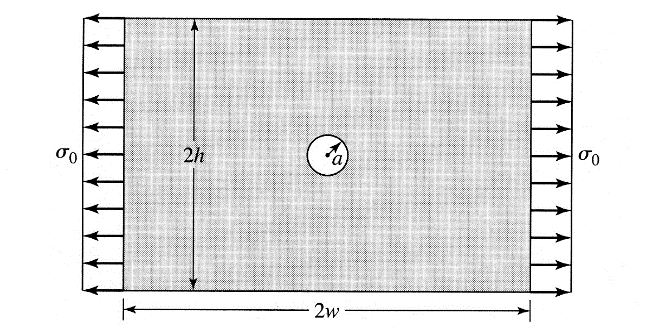


3. Your codes should be easy enough to follow. Here are some ways to improve the readability of your codes:
	Put comments as much as you can!
	Perform different parts of your finite element analysis in different modules and then call the modules in the main body of your code. For example, write separate modules for reading the input file, initialization of equations, assembly of different vectors and matrices, solving the equation systems, and writing the output file.

4. Email your code named Student_ID-Name-Project2.zip to the TA for testing. Also, prepare a short report on what different modules of your code do. Attach to your report the input file for the example system given in part (2) as well as the output file you will obtain from running the code for that example. Hand in the hardcopy of your report in class.


# 前置处理

## 导入库

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.patches import Polygon
import matplotlib as mpl

## 定义单元类和它对应的方法

In [2]:
class Element:
    # 0号节点存为1
    def __init__(self, node1, node2, node3, node4):
        self.bar1 = [node1, node2]
        self.bar2 = [node2, node3]
        self.bar3 = [node3, node4]
        self.bar4 = [node4, node1]
    # 获取单元内四根杆的编号
    def get_bar_index(self, bars):
        index = []
        bar_list = [self.bar1, self.bar2, self.bar3, self.bar4]
        for bar in bar_list:
            if [bar[0]-1,bar[1]-1] in bars:
                index.append(bars.index([bar[0]-1,bar[1]-1]))
            elif [bar[1]-1,bar[0]-1] in bars:
                index.append(bars.index([bar[1]-1,bar[0]-1]))
        return index
    # 获取von-Mises应力
    def get_mises(self, strain, bars, E):
        stress_x = (
            (strain[self.get_bar_index(bars)[0]] + strain[self.get_bar_index(bars)[2]])
            * E
            / 2
        )
        stress_y = (
            (strain[self.get_bar_index(bars)[1]] + strain[self.get_bar_index(bars)[3]])
            * E
            / 2
        )
        return math.sqrt((stress_x - stress_y) ** 2 + stress_x**2 + stress_y**2)
# 判断以该节点为基础是否能生成矩形单元，可以则返回1，反之返回0
def judge(idex, nodes, step):
    if (
        [nodes[idex][0], round(nodes[idex][1] + step["y"], 2)] in nodes
        and [round(nodes[idex][0] + step["x"], 2), round(nodes[idex][1] + step["y"], 2)]
        in nodes
        and [round(nodes[idex][0] + step["x"], 2), nodes[idex][1]] in nodes
    ):
        return 1
    else:
        return 0
# 获取应变-位移矩阵
def B_matrix(i, j, a, b):
    sqrt_3 = math.sqrt(3)
    one_over_3 = 1 / 3
    one_over_4a = 1 / (4 * a)
    one_over_4b = 1 / (4 * b)
    s = [-sqrt_3 * one_over_3, sqrt_3 * one_over_3]
    r = [-sqrt_3 * one_over_3, sqrt_3 * one_over_3]
    B = [
        [
            (s[j] - 1) * one_over_4a,
            0,
            (1 - s[j]) * one_over_4a,
            0,
            (1 + s[j]) * one_over_4a,
            0,
            (-1 - s[j]) * one_over_4a,
            0,
        ],
        [
            0,
            (r[i] - 1) * one_over_4b,
            0,
            (-1 - r[i]) * one_over_4b,
            0,
            (1 + r[i]) * one_over_4b,
            0,
            (1 - r[i]) * one_over_4b,
        ],
        [
            (r[i] - 1) * one_over_4b,
            (s[j] - 1) * one_over_4a,
            (-1 - r[i]) * one_over_4b,
            (1 - s[j]) * one_over_4a,
            (1 + r[i]) * one_over_4b,
            (1 + s[j]) * one_over_4a,
            (1 - r[i]) * one_over_4b,
            (-1 - s[j]) * one_over_4a,
        ],
    ]
    return B
# 获得杆的应变
def get_strain(bar, nodes, nodes_after):
    return math.sqrt(
        (nodes_after[bar[0]][0] - nodes_after[bar[1]][0]) ** 2
        + (nodes_after[bar[0]][1] - nodes_after[bar[1]][1]) ** 2
    ) / math.sqrt(
        (nodes[bar[0]][0] - nodes[bar[1]][0]) ** 2
        + (nodes[bar[0]][1] - nodes[bar[1]][1]) ** 2
    )

## 读取文件

In [3]:
# 使用非国际标准单位
with open("../../input/Perforated thin plate.txt", "r") as f:
    txt = f.readlines()
    Length = float(txt[0].strip())
    Width = float(txt[1].strip())
    R = float(txt[2].strip())
    E = float(txt[3].strip())
    Poisson = float(txt[4].strip())
    Stress = float(txt[5].strip())
    t = float(txt[6].strip())

# 问题求解

## 设置节点并划分单元

In [4]:
# 设置节点密集程度（分为多少段）
density = {"x": 300, "y": 150}
step = {"x": Length / density["x"], "y": Width / density["y"]}
# 获取有效节点
nodes = [
    [x, y]
    for x in np.round(
        np.arange(0, (step["x"] * density["x"] + step["x"]) / 2, step["x"]), 2
    )
    for y in np.round(
        np.arange(0, (step["y"] * density["y"] + step["y"]) / 2, step["y"]), 2
    )
    if x**2 + y**2 >= R**2
]
# 存储杆
bars = []
# 存储单元
elements = []
for node1 in nodes:
    if judge(nodes.index(node1), nodes, step):
        node2 = [round(node1[0] + step["x"], 2), node1[1]]
        node3 = [round(node1[0] + step["x"], 2), round(node1[1] + step["y"], 2)]
        node4 = [node1[0], round(node1[1] + step["y"], 2)]
        elements.append(
            Element(
                nodes.index(node1) + 1,
                nodes.index(node2) + 1,
                nodes.index(node3) + 1,
                nodes.index(node4) + 1,
            )
        )
        if [nodes.index(node1), nodes.index(node2)] not in bars and [
            nodes.index(node2),
            nodes.index(node1),
        ] not in bars:
            bars.append([nodes.index(node1), nodes.index(node2)])
        if [nodes.index(node2), nodes.index(node3)] not in bars and [
            nodes.index(node3),
            nodes.index(node2),
        ] not in bars:
            bars.append([nodes.index(node2), nodes.index(node3)])
        if [nodes.index(node3), nodes.index(node4)] not in bars and [
            nodes.index(node4),
            nodes.index(node3),
        ] not in bars:
            bars.append([nodes.index(node3), nodes.index(node4)])
        if [nodes.index(node4), nodes.index(node1)] not in bars and [
            nodes.index(node1),
            nodes.index(node4),
        ] not in bars:
            bars.append([nodes.index(node4), nodes.index(node1)])

## 获取单元刚度矩阵$\left[k_e\right]$
- 薄板为平面应力状态

In [6]:
# 材料属性矩阵
D = (
    E
    / (1 - Poisson ** 2)
    * np.asmatrix([[1, Poisson, 0], [Poisson, 1, 0], [0, 0, (1 - Poisson) / 2]])
)
# 单元刚度矩阵
a = step["x"] / 2
b = step["y"] / 2
W_i = 1
W_j = 1
B_matrices = np.array([B_matrix(i, j, a, b) for i in range(2) for j in range(2)])
k_e = np.zeros((8, 8))
for B in B_matrices:
    k_e += W_i * W_j * np.dot(np.dot(B.T, D), B)
k_e *= t * a * b
k_e = np.round(k_e, 10)
if np.array_equal(k_e.T,k_e):
    print("k_e为对称阵")

k_e为对称阵


## 装配全局刚度矩阵$\left[K\right]$

In [7]:
n = 2 * len(nodes)
K = np.zeros((n, n))
for element in elements:
    vector = [
        2 * element.bar1[0] - 1,
        2 * element.bar1[0],
        2 * element.bar2[0] - 1,
        2 * element.bar2[0],
        2 * element.bar3[0] - 1,
        2 * element.bar3[0],
        2 * element.bar4[0] - 1,
        2 * element.bar4[0],
    ]
    for i in range(len(vector)):
        for j in range(len(vector)):
            K[vector[i] - 1][vector[j] - 1] += k_e[i][j]
# 检查装配是否正确
if np.array_equal(K.T, K):
    print("K为对称阵")

K为对称阵


## 求解控制方程
$\left[K\right]\{U\}=\{F\}$

In [8]:
# 初始化F矩阵
F = np.zeros(n).T

for node in nodes:
    if node[0] == Length / 2 and node[1] != 0 and node[1] != Width / 2:
        F[2 * nodes.index(node)] = Stress * step["y"]
    elif node[0] == Length / 2 and (node[1] == 0 or node[1] == Width / 2):
        F[2 * nodes.index(node)] = Stress * step["y"] / 2
    if node[0] == 0:
        K[2 * nodes.index(node), :] = 0
        K[:, 2 * nodes.index(node)] = 0
        K[2 * nodes.index(node), 2 * nodes.index(node)] = 1
        F[2 * nodes.index(node)] = 0
    elif node[1] == 0:
        K[2 * nodes.index(node) + 1, :] = 0
        K[:, 2 * nodes.index(node) + 1] = 0
        K[2 * nodes.index(node) + 1, 2 * nodes.index(node) + 1] = 1
        F[2 * nodes.index(node) + 1] = 0

U = np.round(np.dot(np.linalg.inv(K), F), 10)
nodes_after = [
    [node[0] + U[2 * nodes.index(node)], node[1] + U[2 * nodes.index(node) + 1]]
    for node in nodes
]

# 获取每个杆的应变
strain = []
for bar in bars:
    strain.append(get_strain(bar, nodes, nodes_after))

# 计算von-Mises应力
Mises = []
for element in elements:
    Mises.append(element.get_mises(strain, bars, E))

# 绘制变形后的$\sigma_m$分布云图（结论可视化）

C:\Users\ikun\AppData\Local\Temp\ipykernel_10680\2017326928.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  camp = mpl.cm.get_cmap("RdBu", len(elements))


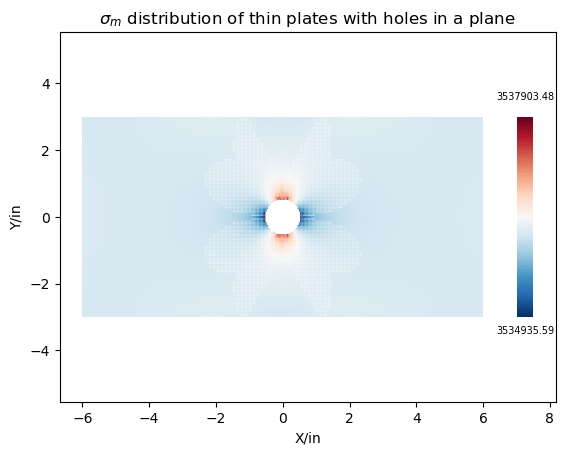

In [9]:
m = max(Mises)
n = min(Mises)

# 根据von-mises应力选取颜色
color = []
camp = mpl.cm.get_cmap("RdBu", len(elements))
Mises_num = [(max(Mises) - x) / (max(Mises) - min(Mises)) for x in Mises]
for i in range(len(elements)):
    color.append(camp(Mises_num[i]))

fig, ax = plt.subplots()
for element in elements:
    bar1 = nodes_after[element.bar1[0] - 1]
    bar2 = nodes_after[element.bar2[0] - 1]
    bar3 = nodes_after[element.bar3[0] - 1]
    bar4 = nodes_after[element.bar4[0] - 1]
    color_index = elements.index(element)

    polygon = Polygon(
        [tuple(bar1), tuple(bar2), tuple(bar3), tuple(bar4)],
        facecolor=color[color_index],
    )
    ax.add_patch(polygon)

    polygon = Polygon(
        [
            (bar1[0], -bar1[1]),
            (bar2[0], -bar2[1]),
            (bar3[0], -bar3[1]),
            (bar4[0], -bar4[1]),
        ],
        facecolor=color[color_index],
    )
    ax.add_patch(polygon)

    polygon = Polygon(
        [
            (-bar1[0], -bar1[1]),
            (-bar2[0], -bar2[1]),
            (-bar3[0], -bar3[1]),
            (-bar4[0], -bar4[1]),
        ],
        facecolor=color[color_index],
    )
    ax.add_patch(polygon)

    polygon = Polygon(
        [
            (-bar1[0], bar1[1]),
            (-bar2[0], bar2[1]),
            (-bar3[0], bar3[1]),
            (-bar4[0], bar4[1]),
        ],
        facecolor=color[color_index],
    )
    ax.add_patch(polygon)

# 绘制colorbar
arr = np.arange(-3, 3 + step["y"], step["y"])
colorbar = np.linspace(0, 1, len(arr) - 1)
color1 = []
for i in colorbar:
    color1.append(camp(i))
for i in range(len(arr) - 1):
    index = np.where(arr == arr[i])[0]  # 获取索引值
    polygon = Polygon(
        [
            (7, arr[i]),
            (7, arr[i] + step["y"]),
            (7.5, arr[i] + step["y"]),
            (7.5, arr[i]),
        ],
        facecolor=color1[-index[0] - 1],  # 使用索引值获取颜色
    )
    ax.add_patch(polygon)
ax.text(7.25, -3.5, str(round(min(Mises), 2)), fontsize=7, ha="center")
ax.text(7.25, 3.5, str(round(max(Mises), 2)), fontsize=7, ha="center")

ax.axis("equal")
ax.set_xlabel("X/in")
ax.set_ylabel("Y/in")
ax.set_title("$\sigma_m$ distribution of thin plates with holes in a plane")
plt.show()

# 与理论解对比

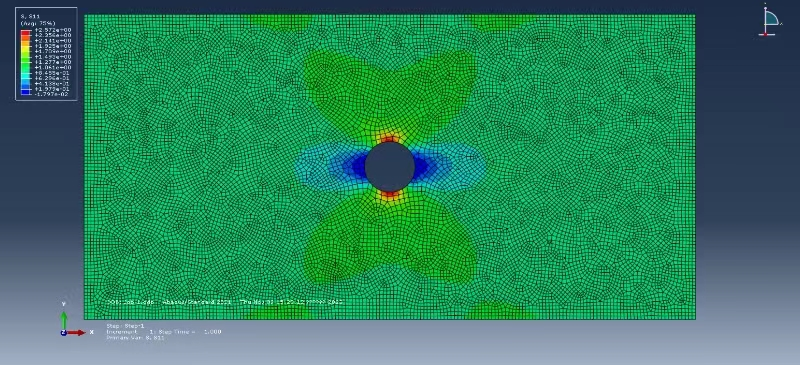

通过与商业软件的运算结果的对比，可知：

1. 薄板的最小应力出现在x方向两侧

2. 最大应力出现在y方向两侧

3. 距离圆孔较远的位置的应力分布差异较小，符合圣维南原理

4. 网格的划分会影响计算结果的精度

综上所述：程序得到的应力分布云图与商业软件的计算结果吻合度较高，计算结果有效，初步实现了平面带孔薄板的有限元方法求解
